# Homework 4

Note \
This homework uses the pinned 2026 lead-scoring release in the course repository. The plan and report are available in cohorts/2026/data/. \
\
In this homework, we will use the 2026 lead-scoring dataset. Download it from here. \
https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv \
\
In this dataset our desired target for classification task will be <u>**converted**</u> variable - has the client signed up to the platform or not.
Data preparation\
\
    Check if the missing values are presented in the features.
    If there are missing values:
        For categorical features, replace them with 'NA'
        For numerical features, replace with with 0.0
\
Split the data into 3 parts with these exact calls: \

    df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1) \
    df_train, df_val = train_test_split( \
        df_full_train, test_size=0.25, random_state=1 \
    ) 

## Submit the results

    Submit your results here: \
    https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw04
    The numerical options are calculated from the pinned 2026 release. Use the value that matches your calculation; do not choose a merely close value.


In [15]:
# HOMEWORK SETUP FOR WEEK 4

##################################################################
# 0.1 - IMPORT PACKAGES
##################################################################
import numpy                      as     np                 # PROVIDES MATH DATA STRUCTURES AND FUNCTIONS
import pandas                     as     pd                 # PROVIDES BASIC ANALYTIC DATA STRUCTURE
import matplotlib.pyplot          as     plt                # USED FOR LINE GRAPHS
from   sklearn.linear_model       import LogisticRegression # 
from   sklearn.model_selection    import train_test_split   # USED TO SPLIT THE DATASET
from   sklearn.feature_extraction import DictVectorizer     # FUNCTION USED TO APPLY ONE-HOT ENCODING
from   sklearn.metrics            import (
                                    accuracy_score,         # 
                                    confusion_matrix,       # 
                                    classification_report,  # 
                                    roc_auc_score           # ROC - AREA UNDER THE CURVE 
                                  )
from   collections                import Counter

#   First, we load the data and clean it: 
#   - column names are lowercased, 
#   - spaces are replaced with underscores, 
#   - totalcharges is converted to numbers with errors='coerce' and 
#   - the missing values are filled with 0, and 
#   - the target is turned into 0/1:

##################################################################
# 0.2 - PREPARE THE DATASET
##################################################################
#   0.2.1 GET CSV AND LOAD DATA INTO A 'pandas' DATAFRAME
url             = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

df              = pd.read_csv(url)

#   0.2.3 CONVERT COLUMN NAMES TO LOWERCASE AND REPLACE WHITESPACES WITH UNDERSCORES
df.columns      = df.columns.str.lower().str.replace(' ', '_')

##################################################################
# 0.3 - EXPLORATORY DATA ANALYSIS
##################################################################
# print(f"COLUMNS BY DATATYPE\r\n{df.dtypes}")
# print()
# print(f"INITIAL COUNT OF MISSING VALUES BY COLUMN \r\n{df.isna().sum()[df.isna().sum() > 0]}")

##################################################################
# 0.4 - CREATE LISTS OF NUMERICAL FEATURES AND CATEGORICAL FEATURES
##################################################################
target            = "converted"

numerical_columns = (
    df.dtypes[
        df.dtypes.isin([np.dtype("int64"), np.dtype("float64")])
    ]
      .index
      .difference([target])  # SKIP THE TARGET COLUMN
      .tolist()
)

categorical_columns = (
    df.select_dtypes(include=["str"])
      .columns
      .difference([target])
      .tolist()
)

##################################################################
# 0.5 - FILL MISSING VALUES 
##################################################################
#   0.5.1 - FIX NUMERICAL DATA VALUES
for col in numerical_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0.0) # FILL MISSING NUMERIC VALUES WITH ZEROS

#   0.5.2 - FIX CATEGORICAL DATA VALUES
for c in categorical_columns:
    df[c]       = df[c].fillna("NA")                      # FILL MISSING VALUES WITH "NA"
    df[c]       = df[c].str.lower().str.replace(' ', '_') # REPLACE WHITESPACES WITH UNDERSCORES 


##################################################################
# 0.6 - SPLIT THE DATATSET
##################################################################
#  SPLIT THE DATASET
#    SPLIT REQUIRES TWO PASSES
#      GOAL: 60% for training, 20% for validation and 20% for test. 
#    SPLIT IS DONE IN TWO STEPS 
#      1. SPLIT OFF INTO A TEST DATASET AND A NOT-TEST (df_full_train) DATASET 
#      2. SPLIT THE NOT-TEST DATASET INTO A TRAINING DATASET AND A VALIDATION DATASET 
#    USE 'random_state=1' SO THE SHUFFLE IS REPRODUCIBLE
df_full_train, df_test = train_test_split(
    df, 
    test_size    = 0.2, 
    random_state = 1 
)

df_train, df_val = train_test_split(
    df_full_train, 
    test_size    = 0.25, 
    random_state = 1
)

#     0.7.2.3 - CREATe TARGET VECTORS AND DROP TARGET FROM TRAIN DATASETS
y_test   = df_test[target].values
# df_test  = df_test.drop(target)
print(f"df_test[target].head(5): \t{df_test[target].head}")

y_train  = df_train[target].values
# df_train = df_train.drop(target)

y_val    = df_val[target].values
# df_val   = df_val.drop(target)


##################################################################
# 0.7 - USE ONE-HOT ENCODING TO CREATE FEATURE AND TARGET DATASETS
##################################################################
# REMINDER: THIS IS THE FUNCTION USED FOR ONE-HOT ENCODING
# from sklearn.feature_extraction import DictVectorizer

#   0.7.1 - CREATE DICTIONARY VECTORIZER INSTANCE 
dv         = DictVectorizer(sparse=False) 

#   0.7.2 - TRAINING DATASETS
#     0.7.2.1 - CREATE TRAINING DICTIONARY
train_dict = df_train[categorical_columns + numerical_columns].to_dict(orient='records')

#     0.7.2.2 - CREATE ONE-HOT ENCODED TRAINING DICTIONARY COLUMNS
X_train    = dv.fit_transform(train_dict)



#   0.7.3 - TRAINING DATASETS
#     0.7.3.1 - CREATE VALIDATION DICTIONARY
val_dict   = df_val[categorical_columns + numerical_columns].to_dict(orient='records')

#     0.7.3.2 - CREATE ONE-HOT ENCODED VALIDATION DICTIONARY COLUMNS
X_val      = dv.transform(val_dict)

#     0.7.3.3 - CREATE TRAIN TARGET VECTOR
y_val      = df_val[target].values

##################################################################
# 0.8 - CREATE THE MODEL
##################################################################
# REMINDER: from   sklearn.linear_model       import LogisticRegression
model = LogisticRegression(solver='lbfgs' , max_iter=10000)
# DEFAULT SOLVER IN NEWER VERSIONS OF 'sklearn': solver='lbfgs'
#   MUST SPECIFY SOLVER EXPLICITLY IN OLDER VERSIONS

# 'fit()' CREATES A MODEL BRIDGING 'X_train' FEATURES TO 'y_train' TARGETS
model.fit(X_train, y_train)


##################################################################
# 0.9 - MAKE PREDICTIONS
##################################################################
# MAKE PREDICTIONS FOR THE VALIDATION DATASET BASED UPON THE TRAINING DATASET
y_pred       = model.predict_proba(X_val)[:, 1]
y_pred_proba = model.predict_proba(X_val)[:, 1]
y_pred       = (y_pred_proba >= 0.5).astype(int)

df_test[target].head(5): 	<bound method NDFrame.head of 2764    0
4767    0
3814    1
3499    0
2735    0
       ..
448     1
921     1
4087    0
1242    1
2242    1
Name: converted, Length: 1000, dtype: int64>


In [16]:
# y_train.shape, y_val.shape, y_test.shape

In [17]:
#df_test.head()
df_test[target].head

<bound method NDFrame.head of 2764    0
4767    0
3814    1
3499    0
2735    0
       ..
448     1
921     1
4087    0
1242    1
2242    1
Name: converted, Length: 1000, dtype: int64>

In [18]:
df_full_train

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
1233,paid_ads,technology,student,europe,38757.0,0,0,0.15,0
1056,paid_ads,healthcare,self_employed,north_america,56516.0,2,6,0.59,1
1686,paid_ads,retail,employed,na,54963.0,1,0,0.13,0
187,social_media,retail,self_employed,na,26237.0,1,5,0.46,0
3840,organic_search,retail,student,north_america,21992.0,3,6,0.70,1
...,...,...,...,...,...,...,...,...,...
2895,paid_ads,manufacturing,na,north_america,66121.0,1,1,0.20,0
2763,paid_ads,manufacturing,employed,north_america,60720.0,4,6,0.69,1
905,na,manufacturing,na,na,49820.0,2,3,0.44,0
3980,organic_search,manufacturing,self_employed,north_america,52228.0,3,5,0.50,0


# Question 1: ROC AUC feature importance

**ROC AUC** could also be used to evaluate feature importance of numerical variables. \
\
Let's do that

    For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
    Use the training dataset for that
 
If your AUC is < 0.5, invert this variable by putting "-" in front \
 \
(e.g. -df_train['balance']) \
 \
AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive. \
 \
Which numerical variable (among the following 4) has the highest AUC?

    * lead_score
    * number_of_courses_viewed
    * interaction_count
    * annual_income


In [19]:
# Q1 WORK
# REMINDER: SOLUTION USES 'from sklearn.metrics import roc_auc_score'

auc_max        = -1.0
for col in numerical_columns:                    # LOOP THROUGH EACY NUMERICAL COLUMN
    scores     = df_train[col].to_numpy()        #   CONVERT NUMERICAL 'pandas' COLUMNS INTO NUMPY ARRAYS
    auc        = roc_auc_score(y_train, scores)  #   CALCULATE ROC_AUC
    
    if auc > auc_max:                            # CHECK WHETHER AUC SCORE IS GREATER THAN THE PREVIOUSLY ENCOUNTERED
        auc_max = auc                            #   IF SO, UPDATE HIGHEST OBSERVED SCORE VALUE
        col_max = col                            #   IF SO, RECORD COLUMN NAME WITH LARGEST SCORE
        
    if auc < 0.5:
        scores = -scores                         # NEGATE 'score' VALUES
        auc    = roc_auc_score(y_train, scores)  # RECALCULATE AUC USING NEGATIVE 'score' VALUES
        if auc > auc_max:                        # CHECK WHETHER AUC SCORE IS GREATER THAN THE PREVIOUSLY ENCOUNTERED
            auc_max = auc                        #   IF SO, UPDATE HIGHEST OBSERVED SCORE VALUE
            col_max = col                        #   IF SO, RECORD COLUMN NAME WITH LARGEST SCORE
            
    print(f"{col}: AUC \t= {auc:.3f}")           # PRINT AUC B COLUMN
    
print()
print("==================================================================")
print(f"ANSWER:\r\n\t'{col_max}' HAS THE GREATEST AUC ({auc_max})")
print("==================================================================")
# ANSWER:
#    'lead_score' HAS THE GREATEST AUC VALUE

annual_income: AUC 	= 0.608
interaction_count: AUC 	= 0.765
lead_score: AUC 	= 0.788
number_of_courses_viewed: AUC 	= 0.723

ANSWER:
	'lead_score' HAS THE GREATEST AUC (0.7882254810906102)


## Question 2: Training the model

Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters: \
\
LogisticRegression(solver='liblinear', C=1.0, max_iter=1000) \
\
What's the AUC of this model on the validation dataset? (round to 3 digits) 

    0.532
    0.632
    0.732
    0.832

In [20]:
##################################################################
# Q2 WORK
##################################################################
#   REMINDER: THESE ARE REQUIRED PACKAGES FOR THIS QUESTION
#     from sklearn.metrics import roc_auc_score
#     from sklearn.linear_model import LogisticRegression
##################################################################

##################################################################
# Q2.1 - SET MODEL PARAMETERS
##################################################################
model      = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)

##################################################################
# Q2.2 - FIT THE MODEL
##################################################################
model.fit(X_train, y_train)

##################################################################
# Q2.3 - MAKE PREDICTIONS
##################################################################
y_val_pred = model.predict_proba(X_val)[:, 1]

##################################################################
# Q2.4 - CALCULATE AUC
##################################################################
auc        = roc_auc_score(y_val, y_val_pred)

##################################################################
# Q2.5 - SUMMARIZE RESULTS
##################################################################
print("==================================================================")
print(f"ANSWER:\r\n\tAUC OF THE MODEL WHEN APPLIED TO VALIDATION:\t{auc:.3f}")
print("==================================================================")

ANSWER:
	AUC OF THE MODEL WHEN APPLIED TO VALIDATION:	0.732


# Question 3: Precision and Recall

Now let's compute precision and recall for our model. 
 
    1. Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
    2. For each threshold, compute precision and recall
    3. Plot them
\
At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall. 

    0.43
    0.63
    0.73
    0.83

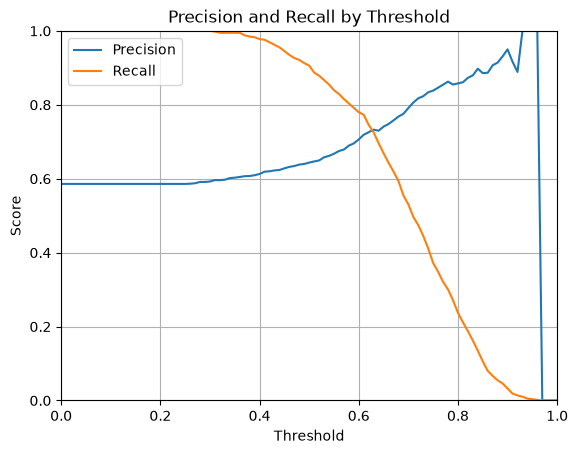

ANSWER:
	PRECISION LINE AND RECALL LINE INTERSECT WITH A THRESHOLD AT 0.63


In [21]:
##################################################################
# Q3.1 - REQUIRED PACKAGES
##################################################################
import numpy             as np
import matplotlib.pyplot as plt
from   sklearn.metrics   import (
                           precision_score, # TP / (TP + FP) # How many predicted positives are actually positive?
                           recall_score     # TP / (TP + FN) # How many actual positives are predicted positive?
                         )

##################################################################
# Q3.2 - INITIALIZE THRESHOLDS, PRECISIONS LIST AND RECALLS LIST
##################################################################
thresholds = np.arange(       # USE 'numpy' TO BUILD A LIST
    start  = 0.0,             #   START VALUE (INCLUSIVE)
    stop   = 1.01,            #   STOP VALUE  (EXCLUSIVE)
    step   = 0.01             #   STEP INTERVAL
)

precisions = []               # LIST FOR PRECISION SCORES
recalls    = []               # LIST FOR RECALL SCORES

##################################################################
# Q2.5 - SUMMARIZE RESULTS
##################################################################
for threshold in thresholds:
    y_pred = (y_val_pred >= threshold).astype(int)
    precisions.append(
        precision_score(      # METHOD FROM 'sklearn.metrics'
            y_val,            #   ACTUAL RESULTS
            y_pred,           #   PREPICTED RESULTS 
            zero_division = 0 #   RETURN ZERO IF CALCULATION WOULD REQUIRE DIVISION BY ZERO
        )
    )
    recalls.append(
        recall_score(
            y_val,            # ACTUAL RESULTS
            y_pred,           # PREPICTED RESULTS 
            zero_division = 0 # RETURN ZERO IF CALCULATION WOULD REQUIRE DIVISION BY ZERO
        )
    )

##################################################################
# Q2.5 - PLOT PRECISION AND RECALL SCORES BY THRESHOLD
##################################################################
plt.plot(thresholds, precisions, label="Precision")
plt.plot(thresholds, recalls,    label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall by Threshold")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()

##################################################################
# Q2.5 - SUMMARIZE RESULTS
##################################################################
print("==================================================================")
print("ANSWER:\r\n\tPRECISION LINE AND RECALL LINE INTERSECT WITH A THRESHOLD AT 0.63")
print("==================================================================")

## FIX!!! Question 4: F1 score

Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both \
\
This is the formula for computing F1:

    F1 = 2 (P*R) / (P+R)
\
Where P is precision and R is recall. \
\
Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01 \
\
At which threshold F1 is maximal?

    0.21
    0.41
    0.61
    0.81

In [22]:
##################################################################
# Q4.1 - CONVERT PRECISION AND RECALL SCORES INTO NUMPY ARRAYS
##################################################################
# NOTE: 'precisions' AND 'recalls' VALUES COME FROM QUESTION 3
# NOTE: 'thresholds' IS DEFINED IN Q3
precisions = np.array(precisions)
recalls    = np.array(recalls)

##################################################################
# Q4.2 - CALCULATE F1 SCORES USING 'numpy'
##################################################################
f1_scores  = np.divide(                    # 'np.divide() PERFORMS AN ELEMENT-BY-ELEMENT DIVISION
    2 * precisions * recalls,              #   NUMERATOR PARAMETER
    precisions + recalls,                  #   DENOMINATOR PARAMETER
    out    = np.zeros_like(precisions),    #   'out=np.zeros_like(precisions)' CREATES A ZERO-FILLED RESULTS ARRAY WITH THE SAME SHAPE AS THE 'precisions' ARRAY
    where  = (precisions + recalls) != 0,
)

##################################################################
# Q4.3 - INITIALIZE MAXIMUM VALUE VARIABLES
##################################################################
max_f1        = -1.0
max_threshold = -1.0

# NOTE: # zip(array_1, array_2)            # 'zip' PAIRS UP ELEMENTS AT SAME INDEX POSITION IN TWO ARRAYS AND RETURNS A 'zip' OBJECT
for threshold, f1 in zip(thresholds, f1_scores):
    print(f"Threshold: {threshold:.2f},\tF1: {f1:.3f}")

    if f1 > max_f1:                        # CHECK WHETHER CURRENT AUC SCORE IS GREATER THAN PREVIOUSLY AUC SCORES
            max_f1        = f1             #   IF SO, STORE HIGHEST OBSERVED SCORE VALUE
            max_threshold = threshold      #   IF SO, STORE COLUMN NAME WITH LARGEST SCORE

##################################################################
# Q4.4 - SUMMARIZE RESULTS
##################################################################
print()
print("==================================================================")
print("NOTE: LARGER 'F1' SCORES INDICATE A BETTER FIT")
print("      'F1' SCORES RANGE FROM ZERO TO ONE")
print("==================================================================")
print(f"ANSWER: \r\n\tMAXIMUM F1\t{max_f1:.3f} \r\n\tTHRESHOLD VALUE\t{max_threshold:.2f}")
print("==================================================================")


Threshold: 0.00,	F1: 0.739
Threshold: 0.01,	F1: 0.739
Threshold: 0.02,	F1: 0.739
Threshold: 0.03,	F1: 0.739
Threshold: 0.04,	F1: 0.739
Threshold: 0.05,	F1: 0.739
Threshold: 0.06,	F1: 0.739
Threshold: 0.07,	F1: 0.739
Threshold: 0.08,	F1: 0.739
Threshold: 0.09,	F1: 0.739
Threshold: 0.10,	F1: 0.739
Threshold: 0.11,	F1: 0.739
Threshold: 0.12,	F1: 0.739
Threshold: 0.13,	F1: 0.739
Threshold: 0.14,	F1: 0.739
Threshold: 0.15,	F1: 0.739
Threshold: 0.16,	F1: 0.739
Threshold: 0.17,	F1: 0.739
Threshold: 0.18,	F1: 0.739
Threshold: 0.19,	F1: 0.739
Threshold: 0.20,	F1: 0.739
Threshold: 0.21,	F1: 0.739
Threshold: 0.22,	F1: 0.739
Threshold: 0.23,	F1: 0.739
Threshold: 0.24,	F1: 0.739
Threshold: 0.25,	F1: 0.739
Threshold: 0.26,	F1: 0.739
Threshold: 0.27,	F1: 0.740
Threshold: 0.28,	F1: 0.743
Threshold: 0.29,	F1: 0.743
Threshold: 0.30,	F1: 0.744
Threshold: 0.31,	F1: 0.747
Threshold: 0.32,	F1: 0.746
Threshold: 0.33,	F1: 0.746
Threshold: 0.34,	F1: 0.750
Threshold: 0.35,	F1: 0.751
Threshold: 0.36,	F1: 0.752
T

## Question 5: 5-Fold CV

Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds: 

    KFold(n_splits=5, shuffle=True, random_state=1)

    Iterate over different folds of df_full_train
    Split the data into train and validation
    Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    Use AUC to evaluate the model on validation
\
How large is standard deviation of the scores across different folds? 

    0.001
    0.007
    0.013
    0.060

In [ ]:
##################################################################
# Q5.1 - REQUIRED PACKAGES
##################################################################
from sklearn.model_selection    import KFold               # IMPLEMENTS K-FOLD SPLITTING
from sklearn.feature_extraction import DictVectorizer      # USED WITH ONE-HOT ENCODING
from sklearn.linear_model       import LogisticRegression  # IMPLEMENTS LINEAR REGRESSION
from sklearn.metrics            import roc_auc_score       # IMPLEMENTS EVALUATION METRICS
import numpy                    as np                      # IMPLEMENTS NUMPY

##################################################################
# Q5.2 - CREATE K-FOLDS
##################################################################
kf                    = KFold(                  # CREATES CROSS-VALIDATION SPLITTER
                          n_splits     = 5,     # CREATE 5 FOLDS WHERE THE LAST ONE IS USED FOR VALIDATION
                          shuffle      = True,  # SHUFFLE ROWS BEFORE DIVIDING THEM
                          random_state = 1      # SET THE RANDOMIZER SEED VALUE
                        )
fold_aucs             = []                      # CREATE LIST TO STORE AUC SCORES

##################################################################
# Q5.3 - LOOP THROUGH FOLDS AND CREATE DICTIONARIES
##################################################################
for fold, (train_idx, val_idx) in enumerate(kf.split(df_full_train), start=1):
    df_fold_train     = df_full_train.iloc[train_idx]
    df_fold_val       = df_full_train.iloc[val_idx]

    X_fold_train_dict = df_fold_train[
        categorical_columns + numerical_columns
    ].to_dict(orient="records")
    
    X_fold_val_dict   = df_fold_val[
        categorical_columns + numerical_columns
    ].to_dict(orient="records")

    
    ##################################################################
    # Q5.4 - VECTORIZE DATAFRAMES
    ##################################################################
    # Fit encoding on this fold's training data only
    dv                = DictVectorizer(sparse=False)
    # dv                = DictVectorizer(sparse=True)
    X_fold_train      = dv.fit_transform(X_fold_train_dict)
    X_fold_val        = dv.transform(X_fold_val_dict)

    y_fold_train      = df_fold_train[target].to_numpy() # CONVERT TARGET LABELS TO A 'numpy' ARRAY
    y_fold_val        = df_fold_val[target].to_numpy()   # CONVERT TARGET LABELS TO A 'numpy' ARRAY
    # NOTE: WITH 'pandas', THE '.to_numpy()' METHOD IS EQUIVALENT TO '.values', BUT GENERALLY PREFERRED AS IT SUPPORTS MORE FEATURES

    ##################################################################
    # Q5.5 - CREATE AND FIT MODEL
    ##################################################################
    model             = LogisticRegression(
                          solver   = "liblinear", # OPTIMIZER ALGORITHM
                          C        = 1.0,         # INVERSE STRENGTH OF REGULARIZATION; 1.0 IS DEFAULT         
                          max_iter = 1000,        # MAXIMUM NUMBER OF ITERATIONS WHEN FITTING FEATURE PARAMETERS TO MODEL
                        )
    model.fit(                                    # FIT MODEL TO DATA
        X_fold_train,                             # TRAINING FEATURES
        y_fold_train                              # TRAINING TARGETS / LABELS
    )

    ##################################################################
    # Q5.6 - SUMMARIZE FOLD RESULTS
    ##################################################################
    y_fold_pred       = model.predict_proba(X_fold_val)[:, 1] #  MAKE PREDICTIONS FOR VALIDATION DATASET
    auc               = roc_auc_score(            # CALCULATE ROC AUC
                          y_fold_val,             # GIVEN VALIATION DATASET FEATURES
                          y_fold_pred             # VALIDATION DATASET TARGETS / LABELS
                        ) 
    
    fold_aucs.append(auc)                         # ADD CURRENT FOLDS' AUC TO THE LIST OF AUCs

    print(f"Fold {fold}: AUC =     \t{auc:.3f}")

##################################################################
# Q5.7 - SUMMARIZE AGGREGATE RESULTS
##################################################################
print("==================================================================")
print(f"  Mean AUC:              \t{np.mean(fold_aucs):.3f}")
print(f"  Standard deviation AUC:\t{np.std(fold_aucs):.3f}")
print("==================================================================")
print(f"ANSWER:\r\n\tSTANDARD DEVIATION ACROSS FOLDS:\t{np.std(fold_aucs):.3f}")
print("==================================================================")

## Question 6: Hyperparameter Tuning

Now let's use 5-Fold cross-validation to find the best parameter C 

    Iterate over the following C values: [0.000001, 0.001, 1]
    Initialize KFold with the same parameters as previously
    Use these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).
\
Which C leads to the best mean ROC AUC? 

    0.000001
    0.001
    1
\
If you have ties, select the score with the lowest std. If you still have ties, select the smallest C.

In [ ]:
##################################################################
# Q6.1 - REQUIRED PACKAGES
##################################################################
from   sklearn.model_selection    import KFold
from   sklearn.feature_extraction import DictVectorizer
from   sklearn.linear_model       import LogisticRegression
from   sklearn.metrics            import roc_auc_score
import numpy                      as     np

##################################################################
# Q6.2 - CREATE SPLITS
##################################################################
kfold             = KFold(
                      n_splits     = 5,     # SPLIT INTO 5 ROUGHLY EQUAL PARTS
                      shuffle      = True,  # RANDOMIZE ORDER BEFORE SPLITTING
                      random_state = 1      # RANDOMIZATION SEED
                    )
c_values          = [0.000001, 0.001, 1]    # USED TO CONTROL DATA REGULARIZATION
                                            #   SMALLER VALUES MEAN GREATER CONTROL
results           = {}                      # EMPTY DICTIONARY TO STORE SCORES FOR 
                                            #   EACH 'c_value'

##################################################################
# Q6.3 - LOOP FOR EACK 'C' REGULARIZATION CONTROL VALUE
##################################################################
print("==================================================================")
for C in c_values:
    aucs              = []  # initialize a list for fold scores

    ##################################################################
    # Q6.3.1 - 'kfold' SPLITS THE 'pandas' DATAFRAME INTO 'k' NUMBER OF FOLDS
    ##################################################################
    for train_idx, val_idx in kfold.split(df_full_train): # CREATE FOLDS BY SPLITTING TRAINNING AND VALIDATION DATASETS INTO 
        ##################################################################
        # Q6.3.2 - SPLIT THE 'pandas' DATAFRAMES WITHIN FOLD
        ##################################################################
        df_fold_train = df_full_train.iloc[train_idx]     # SPLIT TRAIN DATAFRAME WITHIN CURRENT FOLD
        df_fold_val   = df_full_train.iloc[val_idx]       # SPLIT VALIDATION DATAFRAME WITHIN CURRENT FOLD

        ##################################################################
        # Q6.3.3 - CONVERT 'pandas' DATAFRAMES INTO DICTIONARIES FOR 'sklearn'
        ##################################################################
        train_dict    = df_fold_train[                             # CREATE TRAINING DICTIONARY
                          categorical_columns + numerical_columns  #   SELECT FEATURES
                        ].to_dict(orient="records")                #   CONVERT TO A ROW-BASED DICTIONARY; ONE ROW PER RECORD
        val_dict      = df_fold_val[                               # CREATE VALIDATION DICTIONARY
                          categorical_columns + numerical_columns  #   SELECT FEATURES
                        ].to_dict(orient="records")                #   CONVERT TO A ROW-BASED DICTIONARY; ONE ROW PER RECORD

        ##################################################################
        # Q6.3.4 - VECTORIZE THE MODEL FOR 'sklearn'
        ##################################################################
        dv            = DictVectorizer(                            # CREATE DICTIONARY VECTORIZER INSTANCE 
                          sparse = True                            #   'sparse=True' SAVES MEMORY WHEN MOST ELEMENTS ARE ZERO
                        )                
              
        X_fold_train  = (                                          # VECTORIZE TRAINING DATA 
                          dv.fit_transform(train_dict)             #   CALCULATE AND FIT WEIGHTS TO MODEL FEATURES
                            .tocsr()                               #   '.tocsr()' CONVERTS MATRIX INTO A 'sparse' FORMAT
                        )

        X_fold_val    = (                                          #  VECTORIZE VALIDATION DATA
                          dv.transform(val_dict)                   #    PREPARE DATASET TO RECEIVE WEIGHTS AND BIAS FROM TRAINING DATA
                            .tocsr()                               #   '.tocsr()' CONVERTS MATRIX INTO A 'sparse' FORMAT
                        )
        for X in (X_fold_train, X_fold_val):                       # MEET LIBRARY COMPATIBILITY REQUIREMENT 
            X.indices = X.indices.astype(np.int32)                 #   CONVERT INDEX TO 'int32'
            X.indptr  = X.indptr.astype(np.int32)                  #   CONVERT INDEX TO 'int32'

        y_fold_train  = df_fold_train[target].to_numpy()           # GET TRAINING TARGET LABELS
        y_fold_val    = df_fold_val[target].to_numpy()             # GET VALIDATION TARGET LABELS

        
        ##################################################################
        # Q6.3.5 - TRAIN THE MODEL USING 'sklearn'
        ##################################################################
        # MODEL DEFINITION
        model         = LogisticRegression(                        # SELECTED CLASSIFICATION MODEL
                          solver   = "liblinear",                  # OPTIMIZER ALGORITHM
                          C        = C,                            # INVERSE STRENGTH OF REGULARIZATION; 1.0 IS DEFAULT
                          max_iter = 1000,                         # MAXIMUM NUMBER OF ITERATIONS WHEN FITTING FEATURE PARAMETERS TO MODEL
                        )
        ##################################################################
        # Q6.3.6 - TRAIN THE MODEL TO CALCULATE BIAS AND WEIGHTS
        ##################################################################
        model.fit(
            X_fold_train, # TRAINING FEATURES 
            y_fold_train  # ACTUAL TRAINING TARGET LABEL VALUES
        )

        ##################################################################
        # Q6.3.7 - MAKE PREDICTIONS BY APPLYING THE MODEL TO VALIDATION DATA
        ##################################################################
        y_fold_pred   = model.predict_proba(X_fold_val)[:, 1]
        
        
        ##################################################################
        # Q6.3.8 - CALCULATE ROC AUC AND APPEND SCORE TO LIST OF SCORES
        ##################################################################
        aucs.append(roc_auc_score(y_fold_val, y_fold_pred))

    ##################################################################
    # Q6.4 - CREATE AGGREGATE SUMMARY SCORES FOR THE COMPLETE LIST OF 
    #       'C' VALUES CONSIDERED FOR REGULARIZING THE MODEL
    ##################################################################
    results[C]        = (np.mean(aucs), np.std(aucs))
    print(
        f"  C={C}: mean AUC = {results[C][0]:.3f}, "
        f"  std             = {results[C][1]:.3f}"
    )

##################################################################
# Q6.5 - SUMMARIZE RESULTS
##################################################################
best_C            = max(results, key=lambda c: results[c][0])
print("==================================================================")
print(f"ANSWER:\r\n\tSMALLER 'C' VALUES OFFER BETTER CONTROL\r\n\tBest 'C' by mean AUC:\t{best_C}")
print("==================================================================")


In [ ]:
# DEBUG 


In [ ]:
# DEBUG 


In [ ]:
# DEBUG 
df_train

In [ ]:
categorical_columns, numerical_columns